<div style="background:#14110F;border:2px solid #C9A227;border-radius:4px;padding:50px 30px;text-align:center;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:8px;font-size:12px;">RED &amp; WHITE SKILL EDUCATION &nbsp;·&nbsp; SUPERVISED LEARNING</div>
<div style="color:#EAE0CC;font-size:44px;margin:18px 0 6px 0;">Predictive Insight Engine</div>
<div style="color:#C9A227;font-size:16px;font-style:italic;">House Price Prediction with Regression &amp; Gradient Descent</div>
<div style="width:90px;height:1px;background:#C9A227;margin:22px auto;"></div>
<div style="color:#a89f8d;font-size:13px;">Role: Junior Data Scientist &nbsp;|&nbsp; Dataset: 4,200 houses &nbsp;|&nbsp; Target: house_price_inr</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Table of Contents</div>

<b style="color:#C9A227">A</b> Theory &nbsp;·&nbsp; <b style="color:#C9A227">B</b> Data &amp; Preparation &nbsp;·&nbsp; <b style="color:#C9A227">C</b> Simple Linear Regression &nbsp;·&nbsp;
<b style="color:#C9A227">D</b> Evaluation Metrics<br><b style="color:#C9A227">E</b> Multiple Linear Regression &nbsp;·&nbsp; <b style="color:#C9A227">F</b> Polynomial Regression &nbsp;·&nbsp;
<b style="color:#C9A227">G</b> Gradient Descent &nbsp;·&nbsp; <b style="color:#C9A227">H</b> Bias–Variance &nbsp;·&nbsp; <b style="color:#C9A227">I</b> Final Report
</div>

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Setup</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Imports &amp; Dark Theme</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">One global style so every chart matches the notebook</div>
</div>

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
os.makedirs("images", exist_ok=True)

# ---- Old-money palette: ink black, antique gold, burgundy, sage, parchment ----
GOLD, CREAM, BG, PANEL = "#C9A227", "#EAE0CC", "#14110F", "#1E1A16"
BURG, SAGE, BROWN, SLATE, GRID = "#9B3A4A", "#7F9172", "#B08D57", "#7C8DA0", "#3A332C"
PALETTE = [GOLD, BURG, SAGE, SLATE, BROWN, CREAM]
OLDMONEY = LinearSegmentedColormap.from_list("oldmoney", [BURG, PANEL, GOLD])

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": CREAM, "axes.titlecolor": GOLD,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.grid": True,
    "grid.color": GRID, "grid.alpha": 0.6, "xtick.color": CREAM, "ytick.color": CREAM,
    "text.color": CREAM, "legend.facecolor": BG, "legend.edgecolor": GRID,
    "font.family": "serif", "axes.prop_cycle": plt.cycler(color=PALETTE),
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
})

def show(name):
    """Tidy, save a screenshot into /images, then display."""
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

crore = mtick.FuncFormatter(lambda v, _: f"₹{v/1e7:.2f} Cr")   # axis formatter
inr = lambda v: f"₹{v:,.0f}"                                     # text formatter
RANDOM_STATE = 42
print("Setup complete ✔")

Setup complete ✔


<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part A</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Conceptual Understanding</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">Six short answers — the theory behind everything that follows</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Q1 · Supervised Learning Algorithms</div>
Algorithms that learn from <b>labelled data</b> — every training example has inputs (features) and a known output (target). The model learns the mapping <i>X → y</i> and then predicts y for new, unseen inputs. Examples: Linear Regression, Decision Trees, SVM.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Q2 · Regression vs Classification</div>
<b>Regression</b> predicts a <i>continuous number</i> (house price, temperature) and is judged with MSE / RMSE / R². <b>Classification</b> predicts a <i>discrete class</i> (spam / not spam) and is judged with accuracy / precision / recall. The difference lies in the type of target variable.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Q3 · Simple Linear Regression</div>
Models the relationship between <b>one</b> feature and the target with a straight line: <code>ŷ = β₀ + β₁x</code>. β₁ (slope) is the change in y for a one-unit rise in x; β₀ (intercept) is the predicted y when x = 0. The line is fitted by minimising the sum of squared residuals (Ordinary Least Squares).
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Q4 · Assumptions of Linear Regression</div>
<b>1. Linearity</b> – y is a linear function of the features.<br><b>2. Independence</b> – residuals are not correlated with each other (checked by Durbin–Watson).<br><b>3. Homoscedasticity</b> – residuals have constant variance across all predictions.<br><b>4. Normality of residuals</b> – errors are roughly bell-shaped (matters for confidence intervals).<br><b>5. No multicollinearity</b> – features are not highly correlated with each other (checked by VIF; relevant for multiple regression).
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Q5 · Bias–Variance Trade-Off</div>
<b>Bias</b> is error from over-simplified assumptions; <b>variance</b> is error from being too sensitive to the particular training sample. Expected error = Bias² + Variance + Irreducible noise. Making a model more complex lowers bias but raises variance, so the goal is the sweet spot where total error is smallest.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Q6 · Overfitting &amp; Underfitting</div>
<b>Underfitting</b> (high bias): model is too simple, bad on train <i>and</i> test — e.g. a straight line through clearly curved data. <b>Overfitting</b> (high variance): model memorises noise, great on train but poor on test — e.g. a degree-15 polynomial fitted to 50 points. A large train-vs-test gap signals overfitting.
</div>

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part B</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Dataset Understanding &amp; Preparation</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">Load · inspect · visualise · split</div>
</div>

In [2]:
df = pd.read_excel("RealEstate_HousePrice_Dataset_4200.xlsx")
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
df.head()

Shape: (4200, 12)
Missing values: 0 | Duplicate rows: 0


,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
house_id,4200.0,102100.50,1212.58,100001.0,101050.75,102100.5,103150.25,104200.0
area_sqft,4200.0,1667.36,630.34,450.0,1226.75,1660.0,2084.25,4202.0
bedrooms,4200.0,3.70,1.57,1.0,3.00,4.0,5.00,7.0
bathrooms,4200.0,2.83,1.15,1.0,2.00,3.0,4.00,6.0
location_score,4200.0,5.61,2.14,1.0,4.00,5.7,7.30,10.0
age_years,4200.0,23.83,13.95,1.0,13.00,21.0,32.00,80.0
distance_city_km,4200.0,18.19,8.67,1.0,11.80,17.8,24.20,47.6
lot_size_sqft,4200.0,3366.33,1658.23,800.0,2122.50,3188.0,4364.25,12938.0
has_garage,4200.0,0.64,0.48,0.0,0.00,1.0,1.00,1.0
has_pool,4200.0,0.10,0.29,0.0,0.00,0.0,0.00,1.0


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
The dataset is clean (no missing values, no duplicates). Besides the five features named in the brief (area, bedrooms, bathrooms, location score, age) it carries extra columns — distance to city, lot size, garage, pool, renovation — which I treat as additional candidate features. <code>house_id</code> is only an identifier, so it carries no predictive meaning and is dropped.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q7.</b> Identify independent and dependent variables.
</div>

In [4]:
TARGET = "house_price_inr"
FEATURES = [c for c in df.columns if c not in ("house_id", TARGET)]   # drop the ID column

X, y = df[FEATURES], df[TARGET]
print("Dependent variable   (y):", TARGET)
print("Independent variables (X):", FEATURES)

Dependent variable   (y): house_price_inr
Independent variables (X): ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago']


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
<b>Dependent variable:</b> <code>house_price_inr</code> (what we predict). <b>Independent variables:</b> the 10 remaining columns. <code>house_id</code> is excluded because an ID is just a label, not a property characteristic.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q8.</b> Visualise relationships between features and the target.
</div>

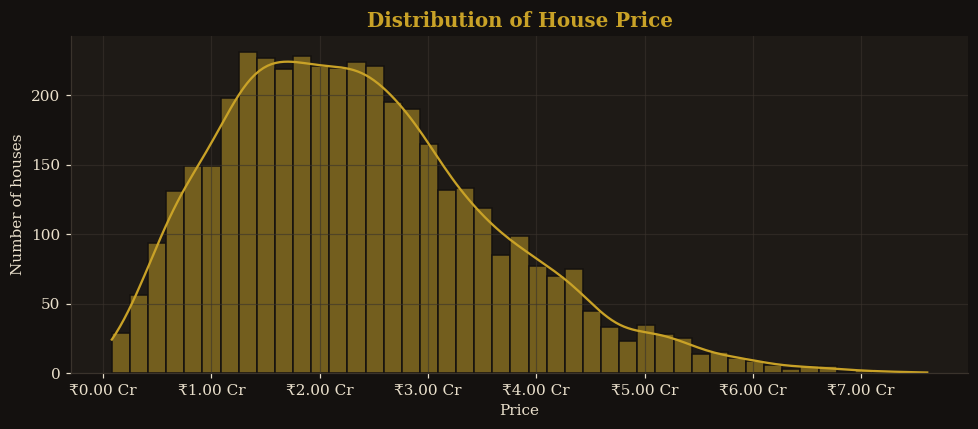

Skewness of price: 0.69


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df[TARGET], bins=45, kde=True, color=GOLD, edgecolor=BG, ax=ax)
ax.xaxis.set_major_formatter(crore)
ax.set(title="Distribution of House Price", xlabel="Price", ylabel="Number of houses")
show("01_price_distribution")
print(f"Skewness of price: {df[TARGET].skew():.2f}")

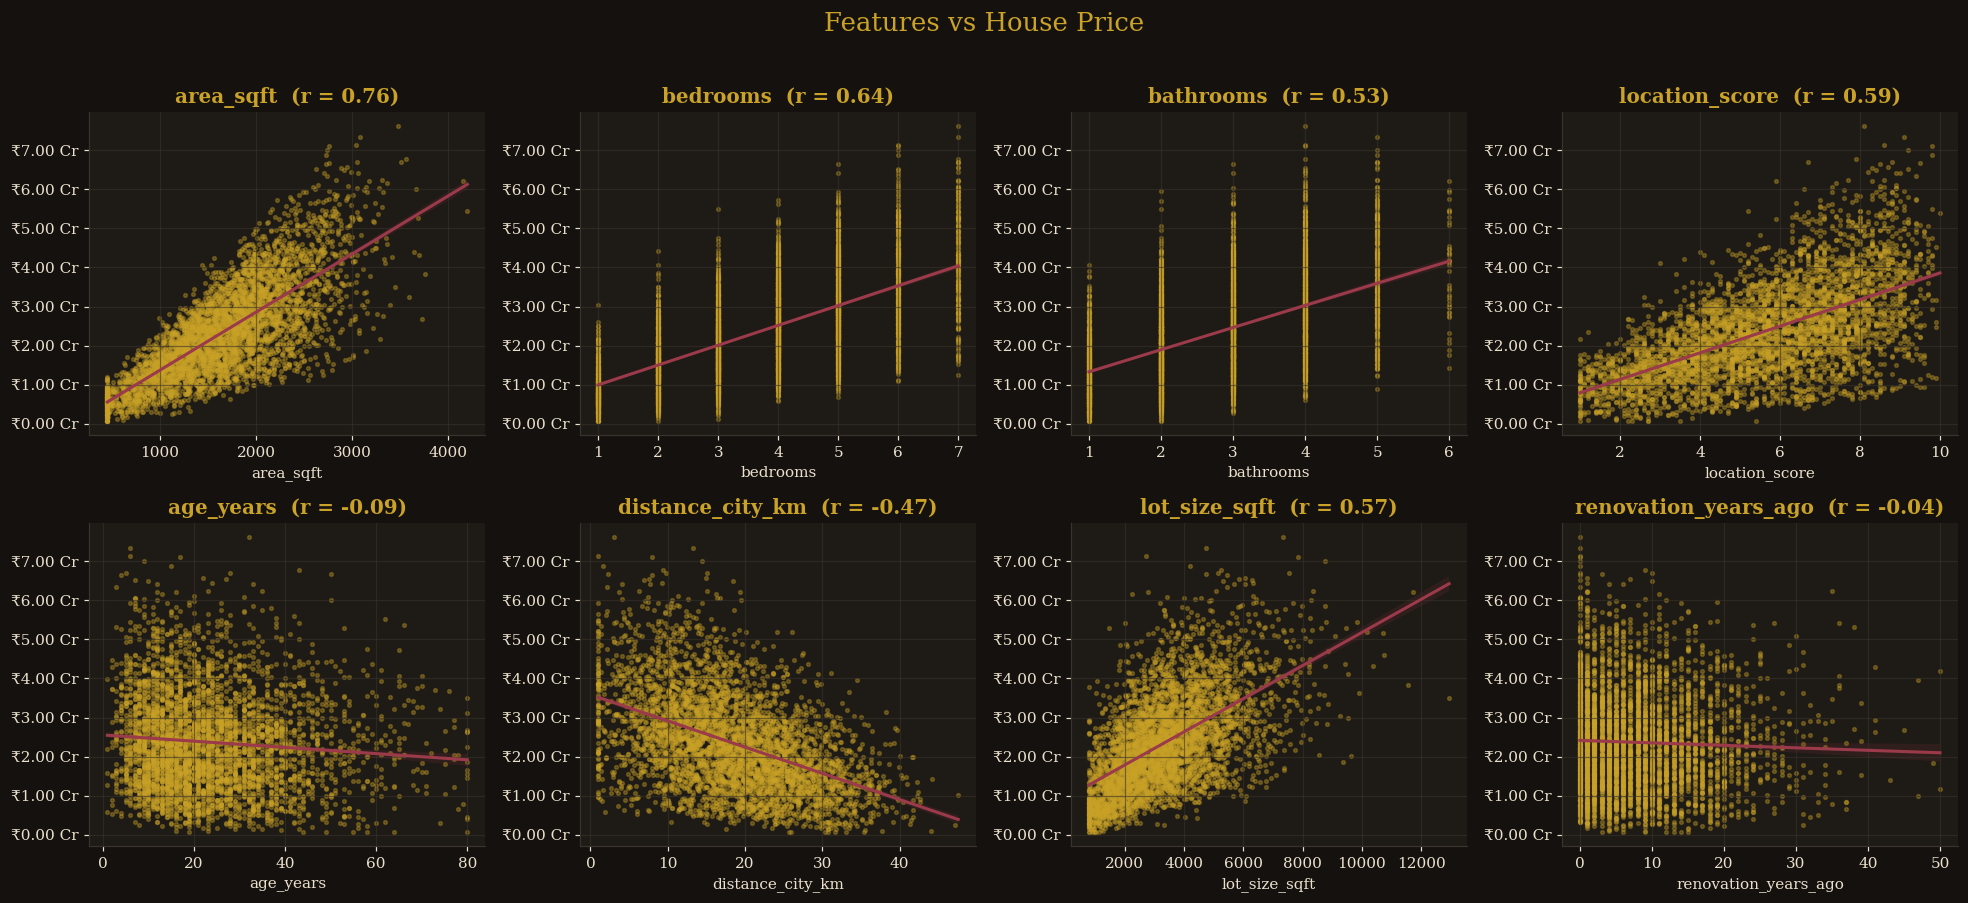

In [6]:
cont = [c for c in FEATURES if df[c].nunique() > 2]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cont):
    ax.scatter(df[c], df[TARGET], s=6, alpha=0.35, color=GOLD)
    sns.regplot(x=df[c], y=df[TARGET], scatter=False, color=BURG, line_kws={"lw": 2}, ax=ax)
    ax.yaxis.set_major_formatter(crore)
    ax.set_title(f"{c}  (r = {df[c].corr(df[TARGET]):.2f})"); ax.set_xlabel(c); ax.set_ylabel("")
for ax in axes.ravel()[len(cont):]: ax.axis("off")
fig.suptitle("Features vs House Price", color=GOLD, fontsize=17, y=1.02)
show("02_features_vs_price")

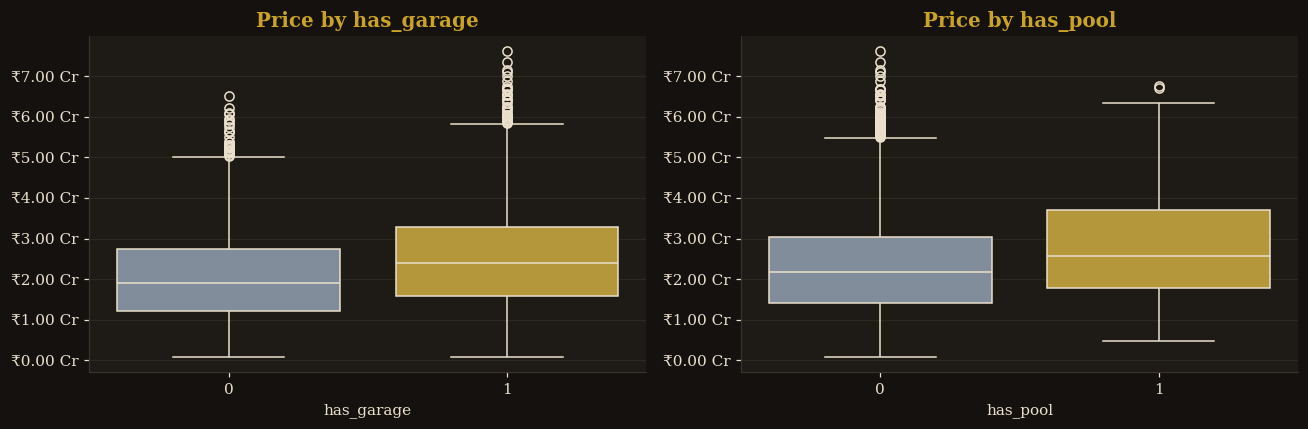

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, ["has_garage", "has_pool"]):
    sns.boxplot(x=df[c], y=df[TARGET], palette=[SLATE, GOLD], ax=ax, linecolor=CREAM, linewidth=1)
    ax.yaxis.set_major_formatter(crore); ax.set(title=f"Price by {c}", ylabel="")
show("03_binary_features_boxplot")

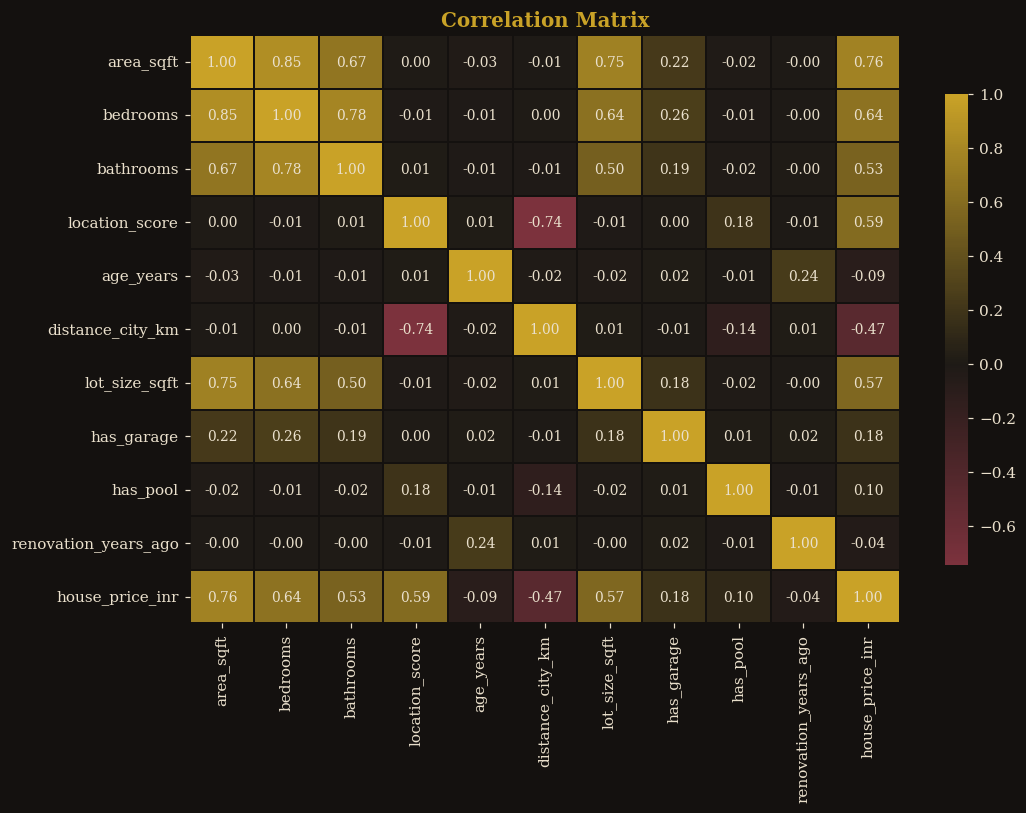

Correlation with price (strongest first):
area_sqft               0.755
bedrooms                0.645
location_score          0.589
lot_size_sqft           0.568
bathrooms               0.527
distance_city_km       -0.469
has_garage              0.177
has_pool                0.102
age_years              -0.089
renovation_years_ago   -0.037


In [8]:
fig, ax = plt.subplots(figsize=(10, 7.5))
corr = df[FEATURES + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap=OLDMONEY, center=0, linewidths=1, linecolor=BG,
            cbar_kws={"shrink": .8}, annot_kws={"color": CREAM, "size": 9}, ax=ax)
ax.set_title("Correlation Matrix"); ax.grid(False)
show("04_correlation_heatmap")
print("Correlation with price (strongest first):")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
<b>area_sqft</b> is the strongest single predictor (r ≈ 0.76), followed by bedrooms, location score, lot size and bathrooms (positive) and distance from the city (negative — farther means cheaper). Age, renovation, garage and pool have weak individual correlations. Bedrooms, bathrooms and area are also correlated with each other, which we will check as <i>multicollinearity</i> in Part E.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q9.</b> Split the dataset into training and testing sets.
</div>

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows (80%)  |  Test: {X_test.shape[0]} rows (20%)")
print(f"Mean price → train {inr(y_train.mean())}  |  test {inr(y_test.mean())}")

Train: 3360 rows (80%)  |  Test: 840 rows (20%)
Mean price → train ₹23,517,754  |  test ₹24,138,414


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
An 80/20 split with a fixed <code>random_state</code> keeps results reproducible. The test set is never used for fitting; the almost identical mean prices show the split is representative.
</div>

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Helper</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">One Scoring Function for Every Model</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">Keeps all comparisons fair and consistent</div>
</div>

In [10]:
results = []   # master leaderboard

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def score(name, model, Xtr, Xte, p=None):
    """Fit-free scoring: model must already be fitted. p = number of predictors used."""
    p = p if p is not None else Xtr.shape[1]
    pred_tr, pred_te = model.predict(Xtr), model.predict(Xte)
    mse = mean_squared_error(y_test, pred_te)
    r2 = r2_score(y_test, pred_te)
    row = {"Model": name, "Predictors": p, "MSE": mse, "MAE": mean_absolute_error(y_test, pred_te),
           "RMSE": np.sqrt(mse), "R2": r2, "Adj_R2": adjusted_r2(r2, len(y_test), p),
           "Train_R2": r2_score(y_train, pred_tr), "Train_RMSE": np.sqrt(mean_squared_error(y_train, pred_tr))}
    results.append(row)
    return row

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part C</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Simple Linear Regression</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">One feature · one line · full diagnostics</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q10.</b> Implement Simple Linear Regression using one feature (House Area).
</div>

In [11]:
slr = LinearRegression().fit(X_train[["area_sqft"]], y_train)
b0, b1 = slr.intercept_, slr.coef_[0]
print(f"price = {b0:,.0f} + {b1:,.2f} × area_sqft")

price = -1,163,519 + 14,788.31 × area_sqft


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q11.</b> Plot the regression line and interpret slope and intercept.
</div>

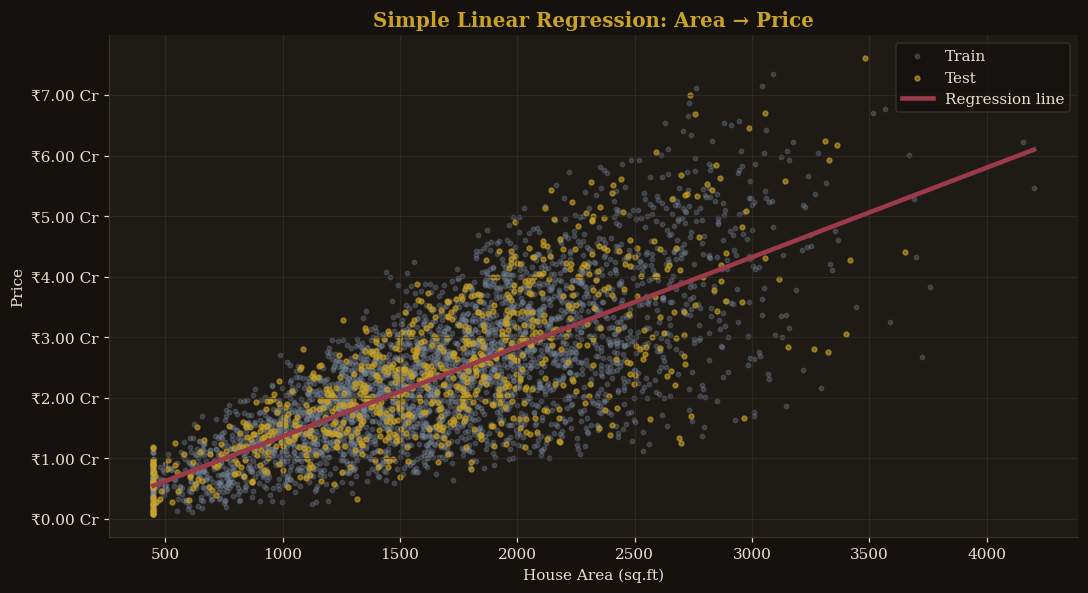

Slope     : 14,788.31  → each extra sq.ft adds about ₹14,788 to the price.
Intercept : -1,163,519 → predicted price of a house with 0 sq.ft (a mathematical anchor, not a real house).


In [12]:
xs = np.linspace(X["area_sqft"].min(), X["area_sqft"].max(), 200)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(X_train["area_sqft"], y_train, s=8, alpha=0.30, color=SLATE, label="Train")
ax.scatter(X_test["area_sqft"],  y_test,  s=10, alpha=0.60, color=GOLD,  label="Test")
ax.plot(xs, slr.predict(pd.DataFrame({"area_sqft": xs})), color=BURG, lw=3, label="Regression line")
ax.yaxis.set_major_formatter(crore)
ax.set(title="Simple Linear Regression: Area → Price", xlabel="House Area (sq.ft)", ylabel="Price")
ax.legend(); show("05_slr_regression_line")
print(f"Slope     : {b1:,.2f}  → each extra sq.ft adds about {inr(b1)} to the price.")
print(f"Intercept : {b0:,.0f} → predicted price of a house with 0 sq.ft (a mathematical anchor, not a real house).")

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
The slope is the price of one additional square foot. The intercept has no physical meaning at area = 0 (no house has zero area) — it only positions the line. Notice how the scatter <b>fans out</b> as area grows: big houses vary much more in price, which hints at a violated assumption (checked next).
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q12.</b> Validate the linear regression assumptions using plots and observations.
</div>

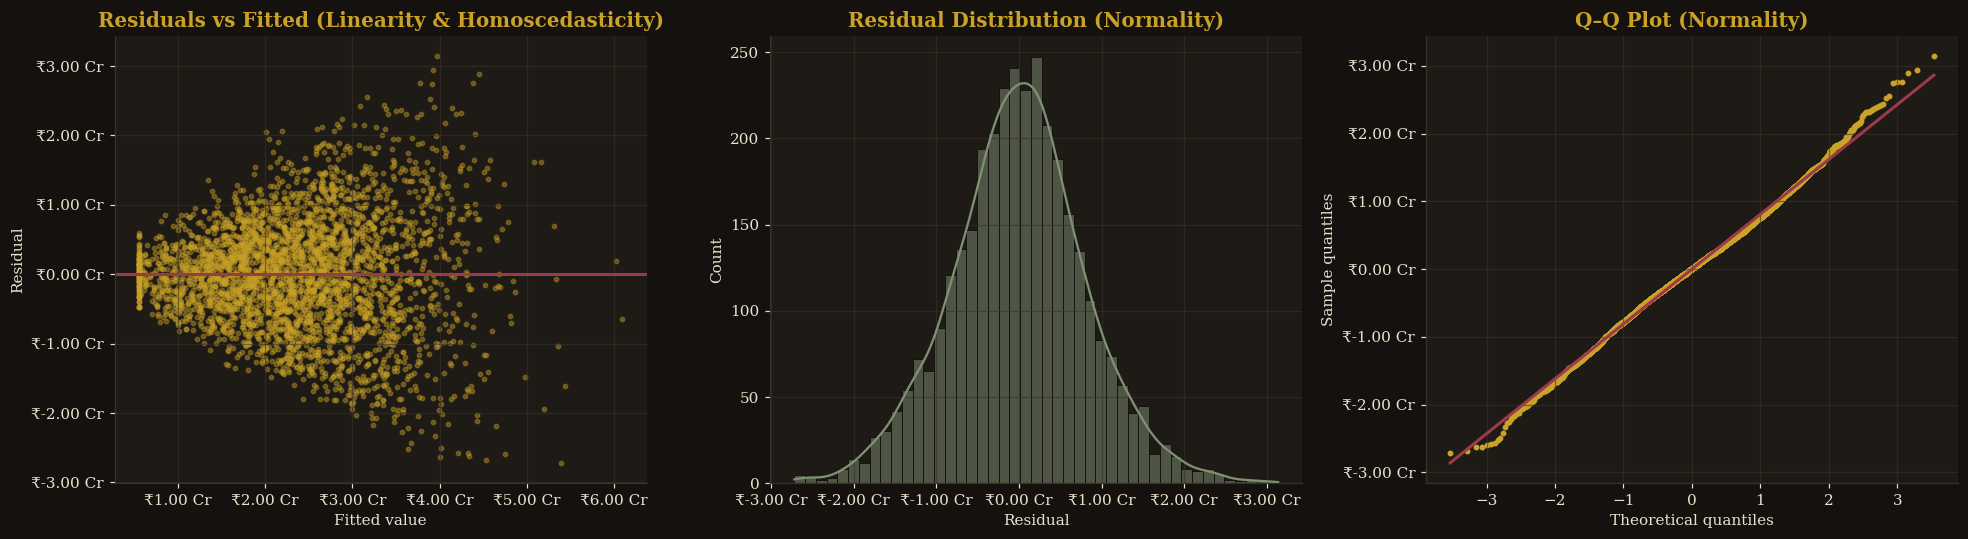

Durbin–Watson (independence)        : 1.98   (≈2 means no autocorrelation)
Spearman |resid| vs fitted (hetero.) : ρ = 0.40, p = 3.4e-128   (ρ ≫ 0 → variance grows with fitted value)
Residual skewness                   : 0.04   (0 = symmetric)
Residual mean                       : 0  (≈ 0 as OLS guarantees)


In [13]:
pred_tr = slr.predict(X_train[["area_sqft"]])
resid = y_train - pred_tr

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(pred_tr, resid, s=8, alpha=0.4, color=GOLD)
axes[0].axhline(0, color=BURG, lw=2)
axes[0].xaxis.set_major_formatter(crore); axes[0].yaxis.set_major_formatter(crore)
axes[0].set(title="Residuals vs Fitted (Linearity & Homoscedasticity)", xlabel="Fitted value", ylabel="Residual")

sns.histplot(resid, bins=45, kde=True, color=SAGE, edgecolor=BG, ax=axes[1])
axes[1].xaxis.set_major_formatter(crore); axes[1].set(title="Residual Distribution (Normality)", xlabel="Residual")

(osm, osr), (slope, intercept, r) = stats.probplot(resid, dist="norm")
axes[2].scatter(osm, osr, s=8, color=GOLD); axes[2].plot(osm, slope*np.array(osm)+intercept, color=BURG, lw=2)
axes[2].yaxis.set_major_formatter(crore); axes[2].set(title="Q–Q Plot (Normality)", xlabel="Theoretical quantiles", ylabel="Sample quantiles")
show("06_slr_assumptions")

# ---- numeric checks ----
dw = np.sum(np.diff(resid.values) ** 2) / np.sum(resid.values ** 2)
rho, p_het = stats.spearmanr(pred_tr, np.abs(resid))
print(f"Durbin–Watson (independence)        : {dw:.2f}   (≈2 means no autocorrelation)")
print(f"Spearman |resid| vs fitted (hetero.) : ρ = {rho:.2f}, p = {p_het:.1e}   (ρ ≫ 0 → variance grows with fitted value)")
print(f"Residual skewness                   : {stats.skew(resid):.2f}   (0 = symmetric)")
print(f"Residual mean                       : {resid.mean():,.0f}  (≈ 0 as OLS guarantees)")

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
<b>Linearity</b> – roughly satisfied (the residuals centre on zero). <b>Independence</b> – Durbin–Watson ≈ 2, no autocorrelation. <b>Homoscedasticity</b> – <i>violated</i>: the residual spread widens for expensive houses (positive Spearman ρ). <b>Normality</b> – residual skewness is close to 0, so the histogram and Q–Q plot are roughly symmetric and bell-shaped (mild tail deviations only). Conclusion: linearity, independence and normality hold reasonably, but the non-constant variance and a modest R² show that one feature is not enough; more features should help.
</div>

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part D</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Model Evaluation Metrics</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">MSE · MAE · RMSE · R² · Adjusted R²</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q13.</b> Evaluate the Simple Linear Regression model.
</div>

In [14]:
row = score("Simple Linear (area)", slr, X_train[["area_sqft"]], X_test[["area_sqft"]], p=1)
metrics = pd.DataFrame({"Value": [row["MSE"], row["MAE"], row["RMSE"], row["R2"], row["Adj_R2"]]},
                       index=["MSE", "MAE", "RMSE", "R² Score", "Adjusted R²"])
metrics["Value"] = [f"{row['MSE']:,.0f}", inr(row["MAE"]), inr(row["RMSE"]), f"{row['R2']:.4f}", f"{row['Adj_R2']:.4f}"]
metrics

,Value
MSE,"66,989,260,021,849"
MAE,"₹6,294,594"
RMSE,"₹8,184,697"
R² Score,0.5625
Adjusted R²,0.5620


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q14.</b> Interpret each metric.
</div>

In [15]:
mean_price = y_test.mean()
print(f"MSE   = {row['MSE']:.3e} → average squared error; punishes big mistakes heavily, but is in ₹² so hard to read.")
print(f"MAE   = {inr(row['MAE'])} → on average the prediction is this far from the true price ({row['MAE']/mean_price:.1%} of the average price).")
print(f"RMSE  = {inr(row['RMSE'])} → typical error in ₹ (sensitive to outliers); RMSE > MAE means some predictions miss by a lot.")
print(f"R²    = {row['R2']:.3f} → area alone explains {row['R2']:.1%} of the variation in price; the rest is unexplained.")
print(f"Adj R²= {row['Adj_R2']:.3f} → R² corrected for number of predictors; nearly equal here because we only used 1 feature.")

MSE   = 6.699e+13 → average squared error; punishes big mistakes heavily, but is in ₹² so hard to read.
MAE   = ₹6,294,594 → on average the prediction is this far from the true price (26.1% of the average price).
RMSE  = ₹8,184,697 → typical error in ₹ (sensitive to outliers); RMSE > MAE means some predictions miss by a lot.
R²    = 0.563 → area alone explains 56.3% of the variation in price; the rest is unexplained.
Adj R²= 0.562 → R² corrected for number of predictors; nearly equal here because we only used 1 feature.


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
RMSE &gt; MAE tells us the error distribution has a tail of large misses (consistent with the fan shape seen earlier). A moderate R² means area is important but clearly not the whole story — a good motivation for Part E.
</div>

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part E</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Multiple Linear Regression</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">All relevant features together</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q15.</b> Implement Multiple Linear Regression with all relevant features.
</div>

In [16]:
# Feature relevance check: Variance Inflation Factor (VIF) detects multicollinearity
def vif_table(Xdf):
    Xs = StandardScaler().fit_transform(Xdf)
    out = []
    for i, c in enumerate(Xdf.columns):
        others = np.delete(Xs, i, axis=1)
        r2 = LinearRegression().fit(others, Xs[:, i]).score(others, Xs[:, i])
        out.append((c, 1 / (1 - r2)))
    return pd.DataFrame(out, columns=["Feature", "VIF"]).sort_values("VIF", ascending=False).round(2)

vif = vif_table(X_train)
print(vif.to_string(index=False))
print("\nRule of thumb: VIF < 5 is fine, 5–10 is moderate, > 10 is serious multicollinearity.")

             Feature  VIF
            bedrooms 5.13
           area_sqft 4.90
           bathrooms 2.59
       lot_size_sqft 2.32
      location_score 2.32
    distance_city_km 2.27
          has_garage 1.07
           age_years 1.06
renovation_years_ago 1.06
            has_pool 1.04

Rule of thumb: VIF < 5 is fine, 5–10 is moderate, > 10 is serious multicollinearity.


In [17]:
mlr = LinearRegression().fit(X_train, y_train)
row_mlr = score("Multiple Linear (all)", mlr, X_train, X_test)

coef = pd.DataFrame({"Feature": FEATURES, "Coefficient (₹ per unit)": mlr.coef_}).sort_values("Coefficient (₹ per unit)")
coef["Coefficient (₹ per unit)"] = coef["Coefficient (₹ per unit)"].round(0)
print("Intercept:", inr(mlr.intercept_)); coef.set_index("Feature")

Intercept: ₹-14,766,763


,Coefficient (₹ per unit)
Feature,
distance_city_km,-98965.0
age_years,-65609.0
renovation_years_ago,-21436.0
lot_size_sqft,104.0
area_sqft,13796.0
has_garage,93924.0
bathrooms,185945.0
bedrooms,197643.0
has_pool,455290.0


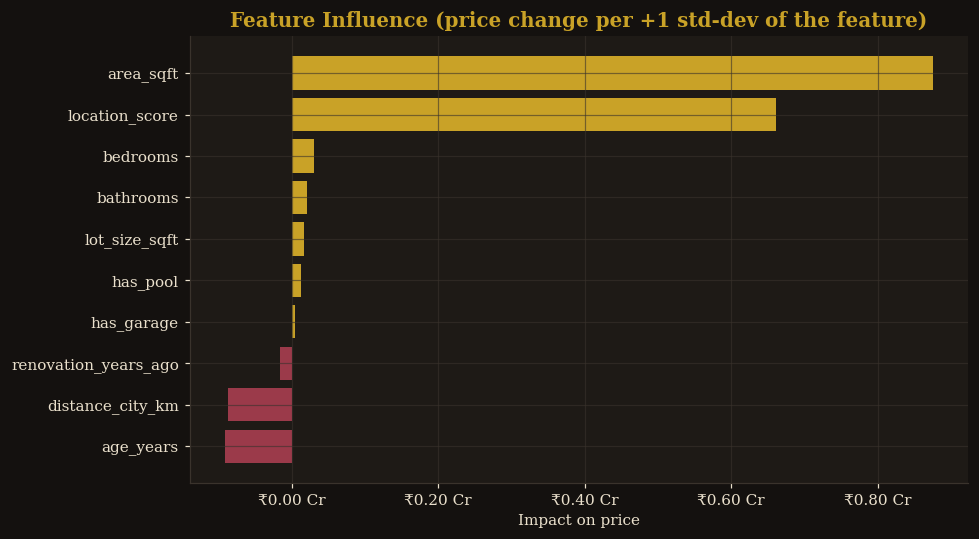

In [18]:
# Standardised coefficients = fair comparison of feature importance
std_coef = pd.Series(mlr.coef_ * X_train.std().values, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(std_coef.index, std_coef.values, color=[BURG if v < 0 else GOLD for v in std_coef.values])
ax.xaxis.set_major_formatter(crore)
ax.set(title="Feature Influence (price change per +1 std-dev of the feature)", xlabel="Impact on price")
show("07_mlr_feature_influence")

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
VIFs are below 10 for every feature (bedrooms ≈ 5.1 and area ≈ 4.9 are borderline-moderate because bigger houses have more bedrooms), so all features are kept. Standardised coefficients give the fair ranking: <b>location score and area</b> dominate price, followed by distance from city and age (both negative). Garage and pool add a premium. Every sign matches common sense. Note that bedrooms looks weak here because area already carries most of the same information.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q16.</b> Compare performance with Simple Linear Regression.
</div>

,MAE,RMSE,R2,Adj_R2
Model,,,,
Simple Linear (area),"6,294,594","8,184,697",0.5625,0.5620
Multiple Linear (all),"2,604,991","3,548,650",0.9178,0.9168


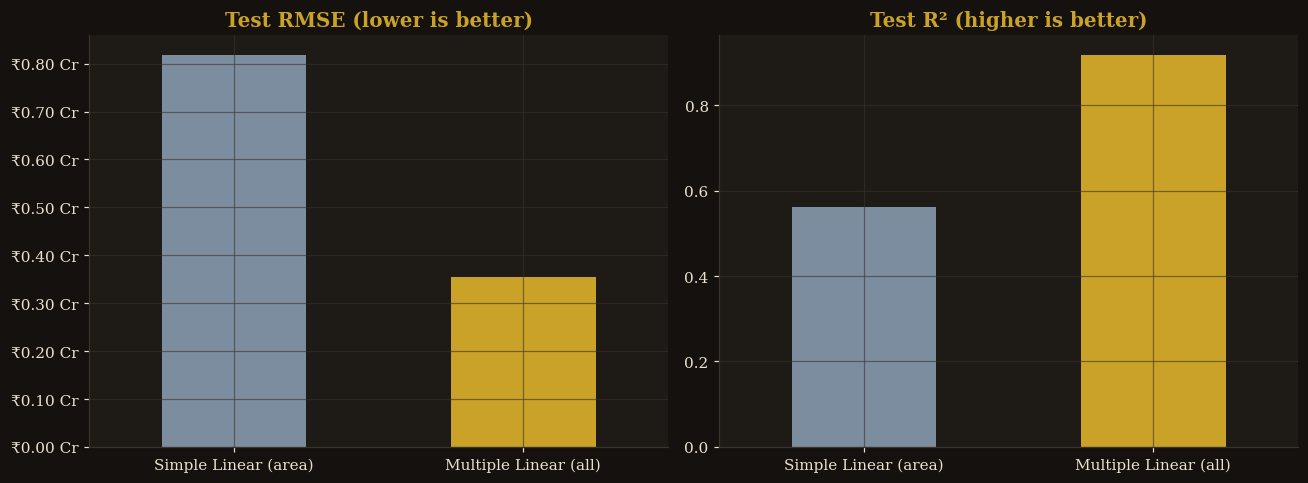

RMSE improved by 56.6% when moving from 1 feature to all features.


In [19]:
cmp = pd.DataFrame(results).set_index("Model")[["MAE", "RMSE", "R2", "Adj_R2"]]
display(cmp.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}", "Adj_R2": "{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cmp["RMSE"].plot.bar(ax=axes[0], color=[SLATE, GOLD], rot=0); axes[0].yaxis.set_major_formatter(crore); axes[0].set_title("Test RMSE (lower is better)"); axes[0].set_xlabel("")
cmp["R2"].plot.bar(ax=axes[1], color=[SLATE, GOLD], rot=0); axes[1].set_title("Test R² (higher is better)"); axes[1].set_xlabel("")
show("08_slr_vs_mlr")
gain = (1 - cmp.loc["Multiple Linear (all)", "RMSE"] / cmp.loc["Simple Linear (area)", "RMSE"])
print(f"RMSE improved by {gain:.1%} when moving from 1 feature to all features.")

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q17.</b> Explain why performance improves or degrades.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
Performance <b>improves</b> because price depends on many factors, not just area. Simple regression lumps the effect of location, bedrooms, distance, etc. into the error term (that is what created the fan-shaped residuals). Multiple regression separates these effects, so it has far lower <b>bias</b>: test R² jumps from about 0.56 to 0.92 and RMSE drops by more than half. With 3,360 training rows for only 10 features, variance stays tiny, and Adjusted R² (0.917 vs 0.562) confirms the extra features earn their place rather than just inflating R².
</div>

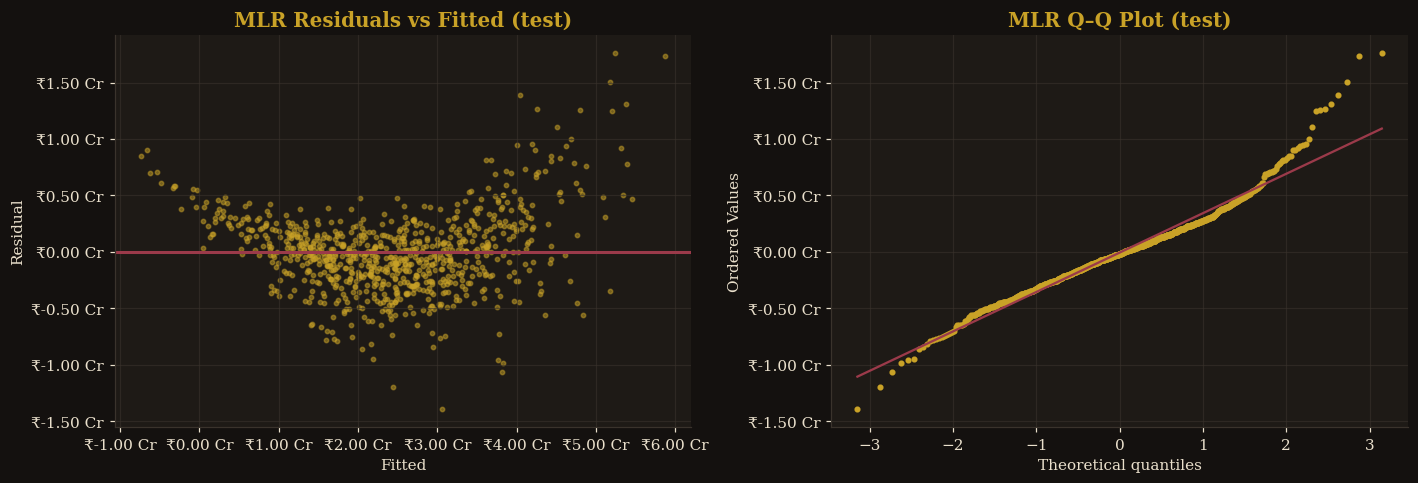

In [20]:
# Re-check residuals for the multiple model
res_m = y_test - mlr.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(mlr.predict(X_test), res_m, s=8, alpha=0.5, color=GOLD); axes[0].axhline(0, color=BURG, lw=2)
axes[0].xaxis.set_major_formatter(crore); axes[0].yaxis.set_major_formatter(crore)
axes[0].set(title="MLR Residuals vs Fitted (test)", xlabel="Fitted", ylabel="Residual")
stats.probplot(res_m, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=GOLD, markersize=3); axes[1].get_lines()[1].set(color=BURG)
axes[1].set_title("MLR Q–Q Plot (test)"); axes[1].yaxis.set_major_formatter(crore)
show("09_mlr_residuals")

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part F</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Polynomial Regression</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">Adding curvature and interactions — and watching for overfitting</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q18.</b> Implement Polynomial Regression (degree 2 and 3).
</div>

In [21]:
def poly_model(degree):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())

poly2 = poly_model(2).fit(X_train, y_train)
poly3 = poly_model(3).fit(X_train, y_train)
n2 = poly2[0].transform(X_train[:1]).shape[1]; n3 = poly3[0].transform(X_train[:1]).shape[1]
score("Polynomial deg 2 (all)", poly2, X_train, X_test, p=n2)
score("Polynomial deg 3 (all)", poly3, X_train, X_test, p=n3)
print(f"Degree 2 expands 10 features → {n2} terms | Degree 3 → {n3} terms")

Degree 2 expands 10 features → 65 terms | Degree 3 → 285 terms


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q19.</b> Compare linear vs polynomial regression — visually and numerically.
</div>

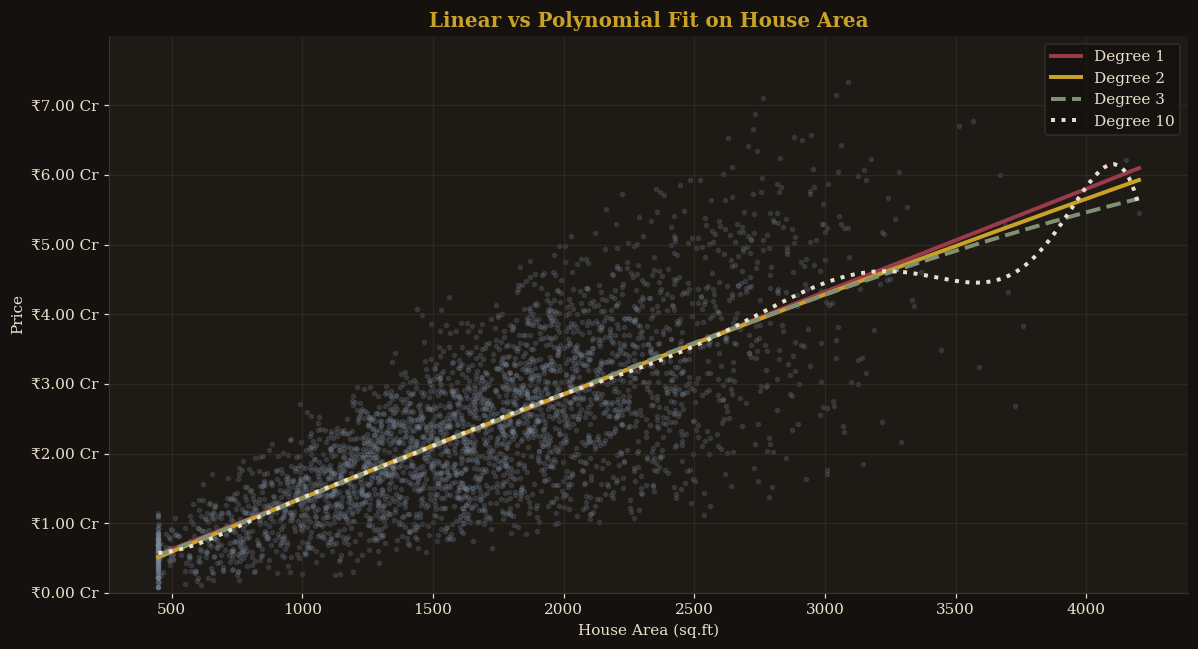

In [22]:
# Visual: single feature (area) so curves can be drawn in 2-D
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(X_train["area_sqft"], y_train, s=7, alpha=0.20, color=SLATE)
for d, col, ls in [(1, BURG, "-"), (2, GOLD, "-"), (3, SAGE, "--"), (10, CREAM, ":")]:
    m = poly_model(d).fit(X_train[["area_sqft"]], y_train)
    ax.plot(xs, m.predict(pd.DataFrame({"area_sqft": xs})), color=col, lw=2.6, ls=ls, label=f"Degree {d}")
ax.yaxis.set_major_formatter(crore); ax.set_ylim(0, y.max() * 1.05)
ax.set(title="Linear vs Polynomial Fit on House Area", xlabel="House Area (sq.ft)", ylabel="Price"); ax.legend()
show("10_poly_curves_area")

In [23]:
# Numeric: all four models side by side
board = pd.DataFrame(results).set_index("Model")[["MAE", "RMSE", "R2", "Adj_R2", "Train_R2"]]
display(board.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}", "Adj_R2": "{:.4f}", "Train_R2": "{:.4f}"})
        .background_gradient(subset=["R2"], cmap=OLDMONEY))

,MAE,RMSE,R2,Adj_R2,Train_R2
Model,,,,,
Simple Linear (area),"6,294,594","8,184,697",0.5625,0.5620,0.5723
Multiple Linear (all),"2,604,991","3,548,650",0.9178,0.9168,0.9247
Polynomial deg 2 (all),"1,656,923","2,267,045",0.9664,0.9636,0.9685
Polynomial deg 3 (all),"1,707,651","2,326,734",0.9646,0.9465,0.9712


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q20.</b> Identify signs of overfitting or underfitting.
</div>

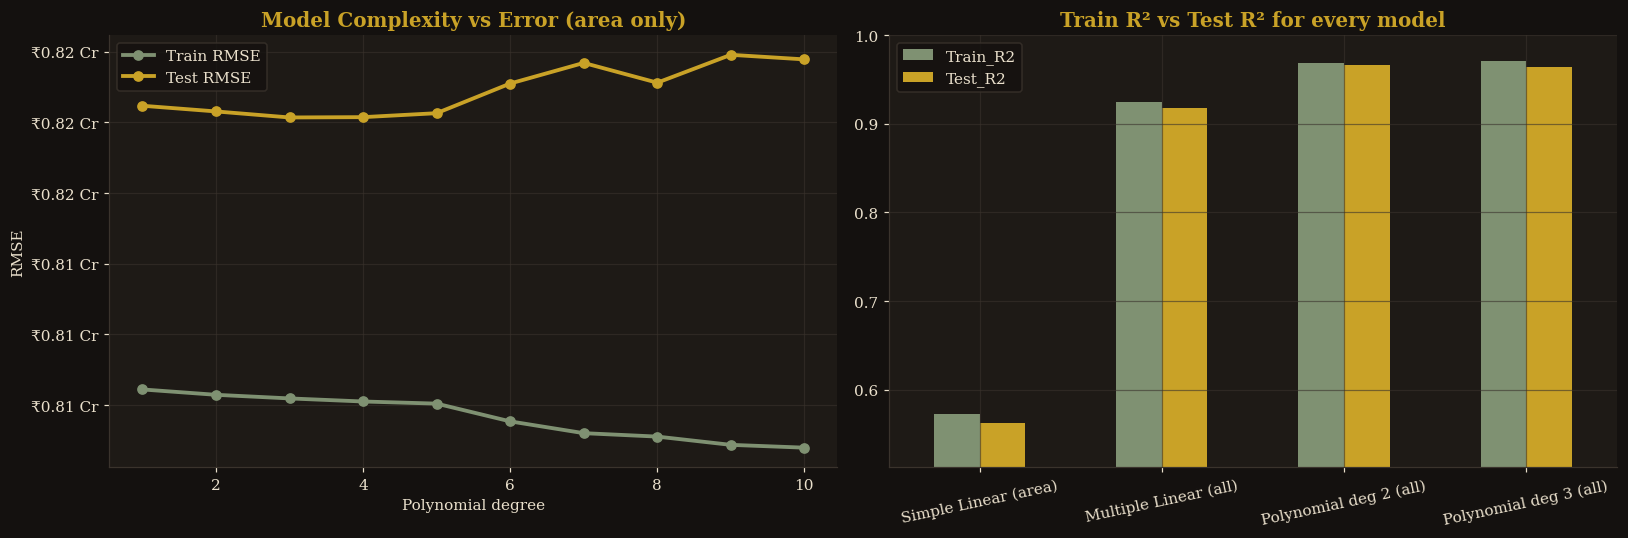

Train − Test R² gap (bigger gap = more overfitting):
Model
Simple Linear (area)      0.0098
Multiple Linear (all)     0.0070
Polynomial deg 2 (all)    0.0020
Polynomial deg 3 (all)    0.0066


In [24]:
# Complexity sweep on area alone: train vs test error as polynomial degree grows
degs = range(1, 11); tr_err, te_err = [], []
for d in degs:
    m = poly_model(d).fit(X_train[["area_sqft"]], y_train)
    tr_err.append(np.sqrt(mean_squared_error(y_train, m.predict(X_train[["area_sqft"]]))))
    te_err.append(np.sqrt(mean_squared_error(y_test,  m.predict(X_test[["area_sqft"]]))))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(degs, tr_err, "o-", color=SAGE, lw=2.5, label="Train RMSE")
axes[0].plot(degs, te_err, "o-", color=GOLD, lw=2.5, label="Test RMSE")
axes[0].yaxis.set_major_formatter(crore)
axes[0].set(title="Model Complexity vs Error (area only)", xlabel="Polynomial degree", ylabel="RMSE"); axes[0].legend()

gap = board[["Train_R2", "R2"]].rename(columns={"R2": "Test_R2"})
gap.plot.bar(ax=axes[1], color=[SAGE, GOLD], rot=12); axes[1].set_ylim(gap.min().min() - 0.05, 1)
axes[1].set(title="Train R² vs Test R² for every model", xlabel="")
show("11_overfitting_check")
print("Train − Test R² gap (bigger gap = more overfitting):")
print((gap["Train_R2"] - gap["Test_R2"]).round(4).to_string())

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
<b>Underfitting</b>: Simple Linear Regression scores low on <i>both</i> train and test (R² ≈ 0.57 / 0.56) — it is too simple. <b>Overfitting</b>: in the left chart (area only) train error keeps falling as the degree grows, while test error stops improving after degree 3–4 and then rises — the classic overfitting signature. On all features the effect is milder but visible: going from degree 2 to degree 3 (65 → 285 terms) raises train R² slightly yet <i>lowers</i> test R² and Adjusted R². Rule: choose the model with the lowest <i>test</i> error, not the lowest train error.
</div>

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part G</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Gradient Descent Optimization</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">Theory · Batch · Stochastic · Mini-Batch — all from scratch with NumPy</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q21.</b> Explain Gradient Descent conceptually.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Gradient Descent — the idea</div>
Imagine standing on a foggy hillside and wanting to reach the valley floor. You feel the slope under your feet and take a step <i>downhill</i>; repeat until the ground is flat. In ML the “hill” is the <b>loss function</b> (MSE) and the position is the set of weights <b>w</b>.<br><br>
<b>Update rule:</b> &nbsp; <code>w ← w − α · ∇L(w)</code> &nbsp; where for linear regression <code>∇L = (2/n) · Xᵀ(Xw − y)</code>.<br>
<b>α (learning rate)</b>: too small → painfully slow; too large → overshoots and diverges.<br><br>
<b>Batch GD</b> uses all n rows per step (smooth, stable, slower per step) · <b>SGD</b> uses 1 random row (very fast, noisy) · <b>Mini-Batch</b> uses a small group, e.g. 64 rows (the practical middle ground).
</div>

In [25]:
# --- Preparation: gradient descent needs scaled features, otherwise it zig-zags or diverges ---
scaler = StandardScaler().fit(X_train)
y_mu, y_sd = y_train.mean(), y_train.std()

add_bias = lambda A: np.c_[np.ones(len(A)), A]
Xb_tr = add_bias(scaler.transform(X_train)); Xb_te = add_bias(scaler.transform(X_test))
ys_tr = ((y_train - y_mu) / y_sd).values

mse_loss = lambda Xb, y, w: np.mean((Xb @ w - y) ** 2)

# Reference: exact (closed-form) least-squares solution = the lowest possible loss
w_ols = np.linalg.lstsq(Xb_tr, ys_tr, rcond=None)[0]
loss_floor = mse_loss(Xb_tr, ys_tr, w_ols)
print(f"Scaled design matrix: {Xb_tr.shape} | Best achievable training loss (OLS): {loss_floor:.5f}")

Scaled design matrix: (3360, 11) | Best achievable training loss (OLS): 0.07526


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q22.</b> Implement Batch Gradient Descent from scratch.
</div>

In [26]:
def batch_gd(Xb, y, lr=0.1, epochs=100):
    w = np.zeros(Xb.shape[1]); hist = [mse_loss(Xb, y, w)]; t0 = time.perf_counter()
    for _ in range(epochs):
        grad = (2 / len(y)) * Xb.T @ (Xb @ w - y)       # gradient over the WHOLE dataset
        w -= lr * grad                                   # one update per epoch
        hist.append(mse_loss(Xb, y, w))
    return w, hist, time.perf_counter() - t0

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q23.</b> Implement Stochastic Gradient Descent (SGD).
</div>

In [27]:
def sgd(Xb, y, lr=0.005, epochs=100, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    w = np.zeros(Xb.shape[1]); hist = [mse_loss(Xb, y, w)]; t0 = time.perf_counter()
    for _ in range(epochs):
        for i in rng.permutation(len(y)):                # shuffle, then visit rows one by one
            xi = Xb[i]
            w -= lr * 2 * (xi @ w - y[i]) * xi           # one update per SAMPLE
        hist.append(mse_loss(Xb, y, w))
    return w, hist, time.perf_counter() - t0

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q24.</b> Implement Mini-Batch Gradient Descent.
</div>

In [28]:
def minibatch_gd(Xb, y, lr=0.05, epochs=100, batch_size=64, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    w = np.zeros(Xb.shape[1]); hist = [mse_loss(Xb, y, w)]; t0 = time.perf_counter()
    for _ in range(epochs):
        idx = rng.permutation(len(y))
        for s in range(0, len(y), batch_size):           # one update per MINI-BATCH
            b = idx[s:s + batch_size]
            w -= lr * (2 / len(b)) * Xb[b].T @ (Xb[b] @ w - y[b])
        hist.append(mse_loss(Xb, y, w))
    return w, hist, time.perf_counter() - t0

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q25.</b> Compare convergence behaviour and training time of all three methods.
</div>

In [29]:
EPOCHS = 100
runs = {
    "Batch GD":      batch_gd(Xb_tr, ys_tr, lr=0.1, epochs=EPOCHS),
    "Stochastic GD": sgd(Xb_tr, ys_tr, lr=0.005, epochs=EPOCHS),
    "Mini-Batch GD": minibatch_gd(Xb_tr, ys_tr, lr=0.05, epochs=EPOCHS, batch_size=64),
}

rows = []
for name, (w, hist, secs) in runs.items():
    pred = (Xb_te @ w) * y_sd + y_mu                      # back to rupees
    r2 = r2_score(y_test, pred); mse = mean_squared_error(y_test, pred)
    rows.append({"Method": name, "Updates/epoch": {"Batch GD": 1, "Stochastic GD": len(ys_tr), "Mini-Batch GD": int(np.ceil(len(ys_tr)/64))}[name],
                 "Final train loss": hist[-1], "Gap to OLS": hist[-1] - loss_floor,
                 "Test RMSE": np.sqrt(mse), "Test R²": r2, "Time (s)": secs})
    results.append({"Model": f"{name} (all, from scratch)", "Predictors": len(FEATURES), "MSE": mse, "MAE": mean_absolute_error(y_test, pred),
                    "RMSE": np.sqrt(mse), "R2": r2, "Adj_R2": adjusted_r2(r2, len(y_test), len(FEATURES)),
                    "Train_R2": r2_score(y_train, (Xb_tr @ w) * y_sd + y_mu),
                    "Train_RMSE": np.sqrt(mean_squared_error(y_train, (Xb_tr @ w) * y_sd + y_mu))})
gd_table = pd.DataFrame(rows).set_index("Method")
display(gd_table.style.format({"Final train loss": "{:.5f}", "Gap to OLS": "{:.5f}", "Test RMSE": "{:,.0f}", "Test R²": "{:.4f}", "Time (s)": "{:.3f}"}))

,Updates/epoch,Final train loss,Gap to OLS,Test RMSE,Test R²,Time (s)
Method,,,,,,
Batch GD,1,0.07545,0.00020,"3,558,494",0.9173,0.007
Stochastic GD,3360,0.08273,0.00748,"3,777,585",0.9068,0.854
Mini-Batch GD,53,0.07611,0.00085,"3,590,899",0.9158,0.054


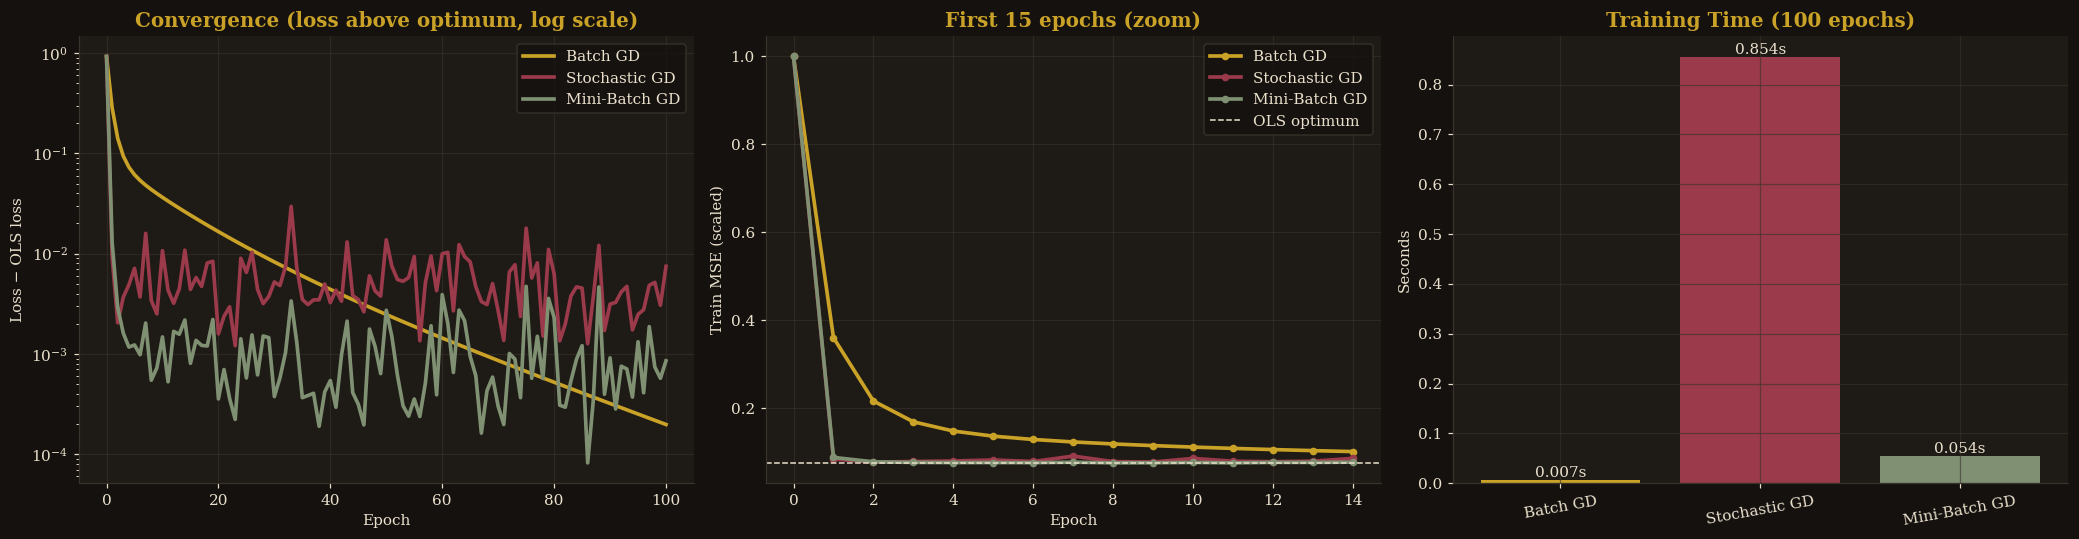

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
cols = {"Batch GD": GOLD, "Stochastic GD": BURG, "Mini-Batch GD": SAGE}

for name, (w, hist, secs) in runs.items():
    axes[0].plot(np.array(hist) - loss_floor + 1e-6, color=cols[name], lw=2.4, label=name)
axes[0].set_yscale("log"); axes[0].set(title="Convergence (loss above optimum, log scale)", xlabel="Epoch", ylabel="Loss − OLS loss"); axes[0].legend()

for name, (w, hist, secs) in runs.items():
    axes[1].plot(np.array(hist[:15]), color=cols[name], lw=2.4, marker="o", ms=4, label=name)
axes[1].axhline(loss_floor, color=CREAM, ls="--", lw=1, label="OLS optimum")
axes[1].set(title="First 15 epochs (zoom)", xlabel="Epoch", ylabel="Train MSE (scaled)"); axes[1].legend()

axes[2].bar(gd_table.index, gd_table["Time (s)"], color=[cols[m] for m in gd_table.index])
axes[2].set(title="Training Time (100 epochs)", ylabel="Seconds"); axes[2].tick_params(axis="x", rotation=10)
for i, v in enumerate(gd_table["Time (s)"]): axes[2].text(i, v, f"{v:.3f}s", ha="center", va="bottom", color=CREAM)
show("12_gradient_descent_comparison")

In [31]:
# Sanity check: do the from-scratch weights match the exact solution?
cmp_w = pd.DataFrame({"OLS (exact)": w_ols, **{k: v[0] for k, v in runs.items()}}, index=["bias"] + FEATURES).round(3)
cmp_w

,OLS (exact),Batch GD,Stochastic GD,Mini-Batch GD
bias,0.000,0.000,-0.024,-0.002
area_sqft,0.706,0.678,0.665,0.700
bedrooms,0.025,0.052,0.022,0.018
bathrooms,0.017,0.010,0.010,0.013
location_score,0.533,0.532,0.537,0.534
age_years,-0.073,-0.074,-0.055,-0.068
distance_city_km,-0.070,-0.071,-0.096,-0.076
lot_size_sqft,0.014,0.023,0.014,0.013
has_garage,0.004,0.003,-0.011,0.000
has_pool,0.011,0.011,0.012,0.003


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
All three optimisers land close to the exact OLS weights and give nearly the same test R² (about 0.91–0.92). The differences are in <i>how</i> they travel. <b>SGD</b> and <b>Mini-Batch</b> drop almost to the optimum within 2 epochs (many updates per epoch) but then jitter around it because each gradient is noisy; SGD jitters the most and ends slightly worse. <b>Batch GD</b> is slower per epoch (one update) but its curve is perfectly smooth and keeps shrinking. In wall-clock time Batch is fastest here because NumPy computes the full gradient in one matrix operation, while SGD is slowest because of its Python loop over 3,360 rows per epoch. <b>Mini-Batch</b> is the practical middle: fast early progress, small noise, modest time.
</div>

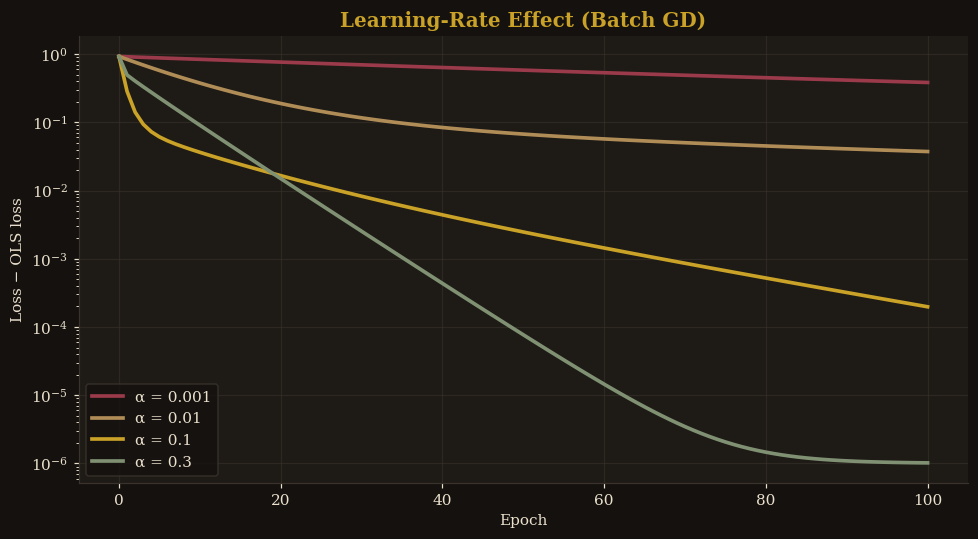

In [32]:
# Bonus: effect of the learning rate (Batch GD)
fig, ax = plt.subplots(figsize=(9, 5))
for lr, col in zip([0.001, 0.01, 0.1, 0.3], [BURG, BROWN, GOLD, SAGE]):
    _, h, _ = batch_gd(Xb_tr, ys_tr, lr=lr, epochs=100)
    ax.plot(np.array(h) - loss_floor + 1e-6, color=col, lw=2.4, label=f"α = {lr}")
ax.set_yscale("log"); ax.set(title="Learning-Rate Effect (Batch GD)", xlabel="Epoch", ylabel="Loss − OLS loss"); ax.legend()
show("13_learning_rate_effect")

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
α = 0.001 is far too slow (barely moved after 100 epochs), α = 0.01 is better but still sluggish, α = 0.1 is good, and α = 0.3 converges almost perfectly within about 80 epochs. Push α much higher and the steps overshoot and the loss diverges. Choosing α is the key hyper-parameter of gradient descent.
</div>

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part H</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Bias–Variance &amp; Model Diagnostics</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">Measured empirically with 100 bootstrap re-trainings per model</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q26.</b> Analyse bias and variance across Simple, Multiple and Polynomial Regression.
</div>

In [33]:
def bias_variance(make_model, cols, B=100, seed=0):
    """Bootstrap estimate: retrain on B resampled training sets, look at predictions on the fixed test set."""
    rng = np.random.default_rng(seed)
    preds = np.empty((B, len(X_test)))
    for b in range(B):
        idx = rng.integers(0, len(X_train), len(X_train))
        m = make_model().fit(X_train.iloc[idx][cols], y_train.iloc[idx])
        preds[b] = m.predict(X_test[cols])
    bias2 = np.mean((preds.mean(axis=0) - y_test.values) ** 2)   # systematic error (includes irreducible noise)
    var = np.mean(preds.var(axis=0))                             # sensitivity to the training sample
    return bias2 / 1e10, var / 1e10                              # reported in (₹ lakh)² for readable numbers

specs = {"Simple Linear":  (lambda: LinearRegression(), ["area_sqft"]),
         "Multiple Linear": (lambda: LinearRegression(), FEATURES),
         "Poly deg 2":      (lambda: poly_model(2), FEATURES),
         "Poly deg 3":      (lambda: poly_model(3), FEATURES)}

bv = {}
for name, (mk, cols) in specs.items():
    bv[name] = bias_variance(mk, cols)
bv = pd.DataFrame(bv, index=["Bias² (incl. noise)", "Variance"]).T
bv["Bias² + Variance"] = bv.sum(axis=1)
# 5-fold CV for a second opinion
cv = {n: -cross_val_score(mk(), X[cols], y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="neg_root_mean_squared_error").mean()
      for n, (mk, cols) in specs.items()}
bv["5-fold CV RMSE (₹)"] = pd.Series(cv)
display(bv.style.format({"Bias² (incl. noise)": "{:.2f}", "Variance": "{:.3f}", "Bias² + Variance": "{:.2f}", "5-fold CV RMSE (₹)": "{:,.0f}"}))

,Bias² (incl. noise),Variance,Bias² + Variance,5-fold CV RMSE (₹)
Simple Linear,6698.86,4.596,6703.45,"8,124,047"
Multiple Linear,1258.69,4.016,1262.70,"3,439,458"
Poly deg 2,513.95,10.887,524.84,"2,248,573"
Poly deg 3,542.85,61.399,604.25,"2,343,939"


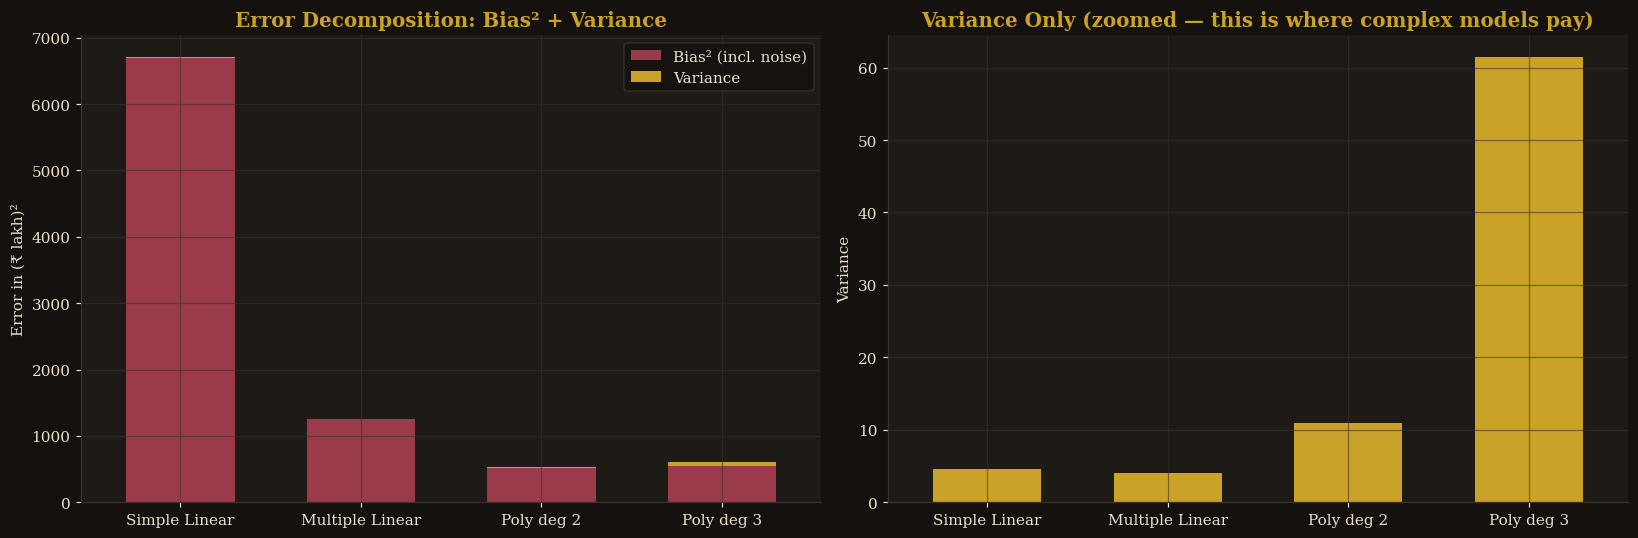

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bv[["Bias² (incl. noise)", "Variance"]].plot.bar(stacked=True, ax=axes[0], color=[BURG, GOLD], rot=0, width=0.6)
axes[0].set(title="Error Decomposition: Bias² + Variance", ylabel="Error in (₹ lakh)²"); axes[0].set_xlabel("")
bv[["Variance"]].plot.bar(ax=axes[1], color=[GOLD], rot=0, width=0.6, legend=False)
axes[1].set(title="Variance Only (zoomed — this is where complex models pay)", ylabel="Variance")
show("14_bias_variance")

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
<b>Simple Linear</b>: very high bias (≈ 6,700) and low variance (≈ 4.6) → <i>underfits</i>. <b>Multiple Linear</b>: bias drops to ≈ 1,260 while variance stays tiny (≈ 4.0). <b>Polynomial deg 2</b>: bias falls again (≈ 514) because the price really has curvature/interaction effects, and variance rises modestly (≈ 11). <b>Polynomial deg 3</b>: bias does not improve (≈ 543) but variance explodes (≈ 61, about 5.6× more) — pure overfitting cost. (Values are in (₹ lakh)² and may vary slightly if re-run.)
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q27.</b> Explain how model complexity affects prediction error.
</div>

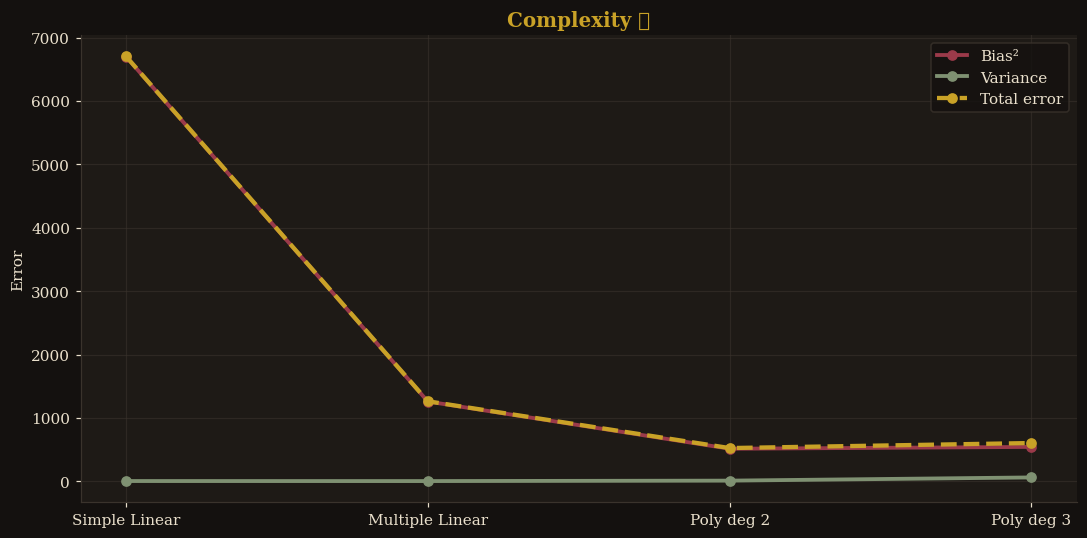

In [35]:
fig, ax = plt.subplots(figsize=(10, 5))
order = ["Simple Linear", "Multiple Linear", "Poly deg 2", "Poly deg 3"]
ax.plot(order, bv.loc[order, "Bias² (incl. noise)"], "o-", color=BURG, lw=2.5, label="Bias²")
ax.plot(order, bv.loc[order, "Variance"], "o-", color=SAGE, lw=2.5, label="Variance")
ax.plot(order, bv.loc[order, "Bias² + Variance"], "o--", color=GOLD, lw=2.8, label="Total error")
ax.set(title="Complexity ➜", ylabel="Error"); ax.legend()
show("15_complexity_vs_error")

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
As complexity increases (left → right) <b>bias falls</b> because the model can represent more patterns, while <b>variance rises</b> because it has more parameters to fit with the same amount of data. Total error is U-shaped: too simple underfits, too complex overfits, and the best model sits near the bottom of the U.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q28.</b> Identify which model best balances bias and variance.
</div>

In [36]:
best_bv = bv["Bias² + Variance"].idxmin()
board = pd.DataFrame(results).set_index("Model")
print(f"Lowest Bias² + Variance : {best_bv}")
print(f"Lowest test RMSE        : {board['RMSE'].idxmin()}  ({inr(board['RMSE'].min())})")
print(f"Lowest 5-fold CV RMSE   : {bv['5-fold CV RMSE (₹)'].idxmin()}")

Lowest Bias² + Variance : Poly deg 2
Lowest test RMSE        : Polynomial deg 2 (all)  (₹2,267,045)
Lowest 5-fold CV RMSE   : Poly deg 2


<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #7F9172;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#7F9172;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Interpretation</div>
<b>Polynomial degree 2</b> is the best balance: it has the lowest Bias² + Variance, the lowest test RMSE and the lowest cross-validated RMSE. Degree 1 models are too biased, and degree 3 adds variance without reducing bias.
</div>

<div style="background:linear-gradient(135deg,#14110F 0%,#241D17 100%);border:1px solid #C9A227;border-radius:6px;padding:22px 28px;margin:10px 0;font-family:Georgia,'Times New Roman',serif;">
<div style="color:#C9A227;letter-spacing:4px;font-size:11px;text-transform:uppercase;">Part I</div>
<div style="color:#EAE0CC;font-size:26px;margin-top:6px;">Final Analysis &amp; Reporting</div>
<div style="color:#a89f8d;font-size:13px;margin-top:6px;font-style:italic;">Leaderboard · findings · business meaning</div>
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q29.</b> Summarise findings.
</div>

,Predictors,MAE,RMSE,R2,Adj_R2,Overfit gap (Train R² − Test R²)
Model,,,,,,
Polynomial deg 2 (all),65,"1,656,923","2,267,045",0.9664,0.9636,0.0020
Polynomial deg 3 (all),285,"1,707,651","2,326,734",0.9646,0.9465,0.0066
Multiple Linear (all),10,"2,604,991","3,548,650",0.9178,0.9168,0.0070
"Batch GD (all, from scratch)",10,"2,611,479","3,558,494",0.9173,0.9163,0.0072
"Mini-Batch GD (all, from scratch)",10,"2,637,241","3,590,899",0.9158,0.9148,0.0081
"Stochastic GD (all, from scratch)",10,"2,759,502","3,777,585",0.9068,0.9057,0.0104
Simple Linear (area),1,"6,294,594","8,184,697",0.5625,0.5620,0.0098


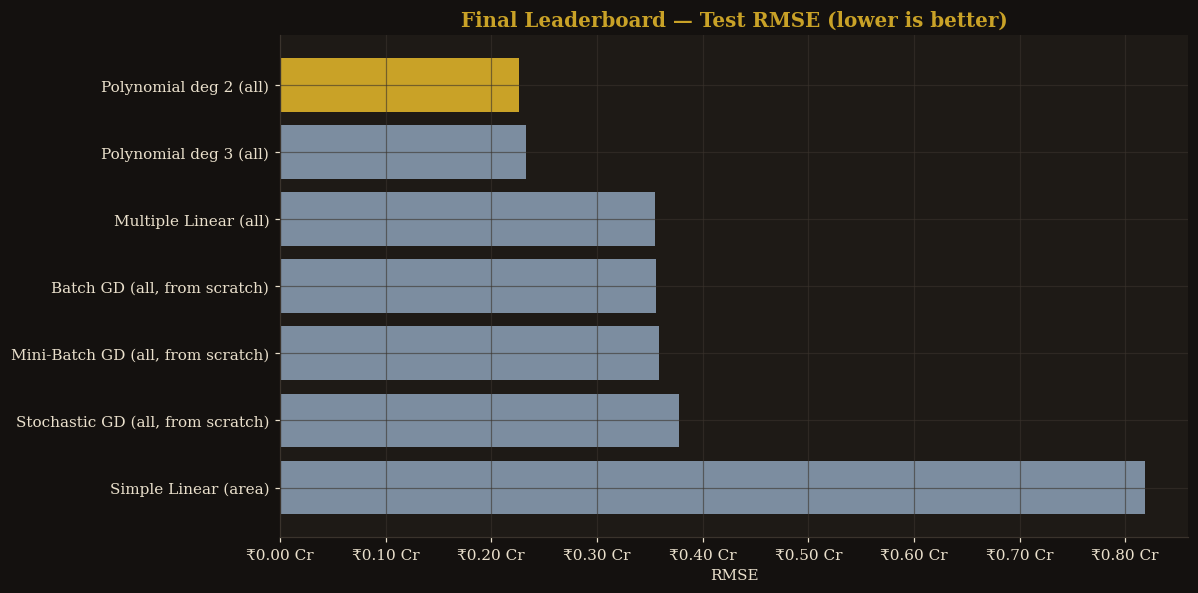

In [37]:
final = pd.DataFrame(results).set_index("Model").sort_values("RMSE")
final["Overfit gap (Train R² − Test R²)"] = final["Train_R2"] - final["R2"]
final.to_csv("model_evaluation_results.csv")
display(final[["Predictors", "MAE", "RMSE", "R2", "Adj_R2", "Overfit gap (Train R² − Test R²)"]].style
        .format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}", "Adj_R2": "{:.4f}", "Overfit gap (Train R² − Test R²)": "{:.4f}"})
        .background_gradient(subset=["R2"], cmap=OLDMONEY))

fig, ax = plt.subplots(figsize=(11, 5.5))
order = final["RMSE"].sort_values(ascending=False)
ax.barh(order.index, order.values, color=[GOLD if m == final.index[0] else SLATE for m in order.index])
ax.xaxis.set_major_formatter(crore); ax.set(title="Final Leaderboard — Test RMSE (lower is better)", xlabel="RMSE")
show("16_final_leaderboard")

In [38]:
best = final.index[0]
print(f"🏆 Best model by test RMSE: {best}")
print(f"   RMSE {inr(final.loc[best,'RMSE'])} | MAE {inr(final.loc[best,'MAE'])} | R² {final.loc[best,'R2']:.4f}")

print("\n💼 Business interpretation (from Multiple Linear Regression, holding other features constant):")
unit = {"area_sqft": "+1 sq.ft", "bedrooms": "+1 bedroom", "bathrooms": "+1 bathroom", "location_score": "+1 location-score point",
        "age_years": "+1 year of age", "distance_city_km": "+1 km from city", "lot_size_sqft": "+1 sq.ft of lot",
        "has_garage": "having a garage", "has_pool": "having a pool", "renovation_years_ago": "+1 year since renovation"}
for f, c in zip(FEATURES, mlr.coef_):
    print(f"   {unit[f]:<28} → {'+' if c>=0 else '-'}{inr(abs(c))}")

🏆 Best model by test RMSE: Polynomial deg 2 (all)
   RMSE ₹2,267,045 | MAE ₹1,656,923 | R² 0.9664

💼 Business interpretation (from Multiple Linear Regression, holding other features constant):
   +1 sq.ft                     → +₹13,796
   +1 bedroom                   → +₹197,643
   +1 bathroom                  → +₹185,945
   +1 location-score point      → +₹3,073,174
   +1 year of age               → -₹65,609
   +1 km from city              → -₹98,965
   +1 sq.ft of lot              → +₹104
   having a garage              → +₹93,924
   having a pool                → +₹455,290
   +1 year since renovation     → -₹21,436


<div style="background:#1E1A16;color:#EAE0CC;border:1px solid #C9A227;border-radius:4px;padding:22px 28px;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.7;">
<div style="color:#C9A227;letter-spacing:4px;font-size:12px;text-transform:uppercase;margin-bottom:8px;">Final Conclusion</div>
<b style="color:#C9A227">Best model.</b> <b>Polynomial Regression (degree 2)</b> on all features is the best performer: test RMSE ≈ ₹22.7 lakh, MAE ≈ ₹16.6 lakh (about 7% of the average price) and R² ≈ 0.966. It captures the curvature and feature interactions (e.g. a good location makes each extra sq.ft worth more) that a straight-line model misses, yet stays simple enough not to overfit. Multiple Linear Regression (R² ≈ 0.918) is the best <i>interpretable</i> model and a strong runner-up; Simple Linear Regression (R² ≈ 0.56) is the weakest.<br>
<b style="color:#C9A227">Impact of gradient descent.</b> Batch, Stochastic and Mini-Batch Gradient Descent, all written from scratch, reproduce the closed-form Multiple Regression result (test R² ≈ 0.917, 0.907 and 0.916 vs 0.918), proving the optimisation is correct. Feature scaling and the learning rate are what make it work. SGD and Mini-Batch converge in about 2 epochs but stay noisy; Batch is smooth and, being fully vectorised, was fastest in wall-clock time on this small dataset.<br>
<b style="color:#C9A227">Overfitting / underfitting.</b> <i>Underfitting</i> – Simple Linear Regression (train R² ≈ 0.57, test ≈ 0.56): high bias. <i>Overfitting</i> – Polynomial degree 3 has higher train R² than degree 2 but lower test and Adjusted R², and its variance is about 5× larger; a high-degree polynomial on area alone shows test error rising while train error keeps falling.<br>
<b style="color:#C9A227">Business meaning.</b> Location score is the single biggest value driver (≈ ₹30.7 lakh per point), followed by size (≈ ₹13.8 thousand per sq.ft), a pool (≈ ₹4.6 lakh), and negative effects from age (≈ −₹65 thousand per year) and distance from the city (≈ −₹99 thousand per km). The firm can use the degree-2 model to price a house within roughly ±₹17–23 lakh on a typical ₹2.4 crore property, and use the coefficients to advise clients on which upgrades and locations add the most value.<br>
<b style="color:#C9A227">Limitations &amp; next steps.</b> Price is right-skewed and its variance grows with size, so predicting <i>log(price)</i>, adding regularisation (Ridge / Lasso) or tree-based models (Random Forest, Gradient Boosting) are natural next experiments.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #9B3A4A;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#9B3A4A;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Task</div>
<b>Q30.</b> Deliverables checklist.
</div>

<div style="background:#1E1A16;color:#EAE0CC;border-left:4px solid #C9A227;border-radius:3px;padding:14px 20px;margin:8px 0;font-family:Georgia,'Times New Roman',serif;font-size:14.5px;line-height:1.6;">
<div style="color:#C9A227;font-size:12px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Submission</div>
✔ Source code (this notebook) &nbsp;·&nbsp; ✔ Evaluation results (<code>model_evaluation_results.csv</code>) &nbsp;·&nbsp; ✔ Graphs (<code>/images</code>) &nbsp;·&nbsp; ✔ Final conclusion (above)
</div>